Je shranilo C:\Users\jakad\OneDrive\Desktop\3d_data\output\mhs_Pivola_my_ass3.tiff


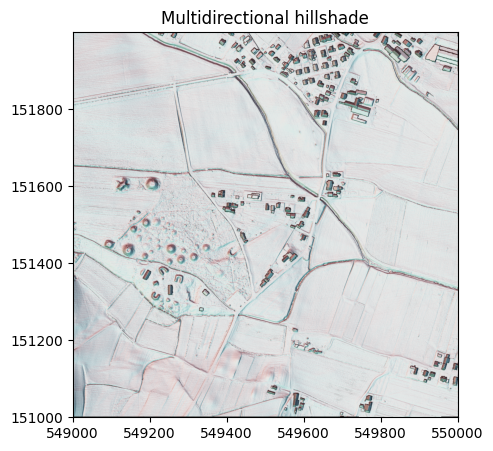

In [ ]:
'''
Avtor / Author: Jaka Dacar 
Nazadnje spremenjeno / Last changed: 25.10.2026

Ta algoritem je uporabljen za uporabo vizualizacijske tehnike - večsmerno senčenje oz. Multidirect Hillshade (v nadaljevanju bom uporabil besedo 'multidirectional hillshade')
That algorithm was made for visualisation tecnique - Multidirectional hillshade (in continute, I will use word 'multidirectional hillshade')


Algoritem je bil ustvarjen v sklopu diplomske naloge 
Algorithm was made as part of bachelor thesis
'''

import numpy as np
import rasterio as rio 
import matplotlib.pyplot as plt
from pathlib import Path 



#-----------------------------------------------------------------------------------------------------------------------------------
#INPUT in OUTPUT
#-----------------------------------------------------------------------------------------------------------------------------------
#vhod pot podatka, za katero imaš namen uporabiti za multidirectional hillshade. Datoteka mora biti nujno shranjena pod .tiff ali .tif
dtm_data = Path(r"C:\Users\jakad\OneDrive\Desktop\3d_data\output\Pivola_klasificirano_in_rastirano.tiff") 

#izhod podatkov, kjer se bo shranila v prostoru, kjer je definiran pot. Datoteka, naj se shrani pod .tiff (bolj priročno) ali .tif
save_path = Path(r"C:\Users\jakad\OneDrive\Desktop\3d_data\output\mhs_Pivola_my_ass3.tiff") 

#-----------------------------------------------------------------------------------------------------------------------------------
#HILLSHADE
#-----------------------------------------------------------------------------------------------------------------------------------
def hillshade(dtm, 
              azimuth=215, 
              altitude=35, 
              cellsize_x=0.5, 
              cellsize_y=0.5, 
              zfactor: float= 1.0
            ):

    
    p = np.pad(dtm, 1, mode="edge")
    a, b, c = p[:-2, :-2], p[:-2, 1:-1], p[:-2, 2:]
    d,    f = p[1:-1, :-2],              p[1:-1, 2:]
    g, h, i = p[2:, :-2],  p[2:, 1:-1],  p[2:, 2:]

    dz_dx = ((c + 2 * f + i) - (a + 2 * d + g)) * zfactor / (8 * cellsize_x)
    dz_dy = ((g + 2 * h + i) - (a + 2 * b + c)) * zfactor / (8 * cellsize_y)

    azimuth_rad = np.radians(360.0 - azimuth + 90.0)
    zenith_rad = np.radians(90.0 - altitude)

    slope = np.arctan(np.hypot(dz_dx, dz_dy))
    aspect = np.arctan2(dz_dy, -dz_dx)

    shaded = (
        np.cos(zenith_rad) * 
        np.cos(slope) +
        np.sin(zenith_rad) * 
        np.sin(slope) * 
        np.cos(azimuth_rad - aspect)
    )

    hs = (255 * np.clip(shaded, 0, 1)).astype(np.float64)
    return hs

#-----------------------------------------------------------------------------------------------------------------------------------
#MUTLIDIRECT HILLSHADE 
#-----------------------------------------------------------------------------------------------------------------------------------
#dodajanje barve, večsmerne svetlobe
def multidirectional_hillshade(
                            dtm,  
                            resolution: float = 0.5,
                            altitude: float = 35.0,
                            n:int = 12, 
                            zfactor: float = 2.0) -> np.ndarray:


    azimuths = np.linspace(0, 360, n, endpoint=False)
    az = azimuths

#na splošno pa koda deluje tako, da je sestavljena iz dveh osnovnih funckij in sicer : azimut (prva številka) in RGB (zadnji tri številke). Na podlagi teh lahko narediš neomejeno različnih kombinacij, ki ti jo lahko prinese sama koda
#'ime': (azimut, Red, Green, Blue).
#pri tem n in az nimata nobene povezave, saj sta povsem ločena
    lights = {          
    
        'warm':   (70, 230, 80, 200),    
        's': (320, 230, 80, 200),         
        'a': (300, 230, 80, 200),         
        'k': (280, 230, 80, 200),         
        'x': (120, 40, 120, 255),         
        'y': (140, 40, 120, 255),      
        'z': (160, 40, 120, 255),        
        'f': (180, 40, 120, 255),       
        'fully1': (0,  190, 190, 190),   
        'g': (210, 190, 190, 190),        
        '4': (200, 190, 190, 190),        
        '.': (240, 190, 190, 190),       
    }

#vključevanje weight z RGB, ki normalizira vsak kanal, da ostanejo v vrednosti med 0 in 1
    rgb = np.zeros(dtm.shape + (3,), dtype=float)
    weight = np.zeros(3, dtype=float)
    for az, r, g, b in lights.values():
        hs = hillshade(dtm,
                    azimuth=az,
                    altitude=altitude,
                    cellsize_x=resolution,
                    cellsize_y=resolution,
                    zfactor=zfactor) / 255.0
        color = np.array([r, g, b]) / 255.0
        rgb += hs[..., None] * color
        weight += color

    return rgb / weight


with rio.open(dtm_data) as ds:
    dtm = ds.read(1, masked=True).filled(np.nan)
    profile = ds.profile
    resolution = ds.res[0]
    ext = (
        ds.bounds.left,
        ds.bounds.right,
        ds.bounds.bottom,
        ds.bounds.top
    )

#izračun naklona oz. slope in glede temnosti senčenja. 
#večji naklon pomeni nižjo slope_term
dzdx, dzdy = np.gradient(dtm, resolution)
slope_deg = np.degrees(np.arctan(np.hypot(dzdx, dzdy)))
slope_term = 1 - np.clip(slope_deg / 45.0, 0, 1) * 0.5
hs = multidirectional_hillshade(dtm, resolution=resolution)
out = (np.nan_to_num(hs * slope_term[..., None]) * 255).astype("float64")

#-----------------------------------------------------------------------------------------------------------------------------------
#SHRANJEVANJE 
#-----------------------------------------------------------------------------------------------------------------------------------

if save_path is not None:   
    if profile is None:
        raise ValueError(f'Manjka geografski {profile} rastra')

    out_profile = profile.copy()
    out_profile.update(
        dtype='float64', 
        count=3, 
        compress='lzw',
        nodata=None
    )
    with rio.open(save_path, 'w', **out_profile) as dst:
        dst.write(out.astype("float64").transpose(2, 0, 1))

    if save_path.exists and save_path.stat().st_size > 0:
        print('Je shranilo', save_path)
    else:
        print('Ni se shranilo')

#-----------------------------------------------------------------------------------------------------------------------------------
#HITER PRIKAZ MULTIDIRECTIONAL HILLSHADE-ja z MATPLOTLIB-om 
#-----------------------------------------------------------------------------------------------------------------------------------

fig, ax = plt.subplots(figsize = (5, 5))

showing = out / np.max(out)

im = ax.imshow(showing, extent=ext)
ax.set_title("Multidirectional hillshade")
ax.axis("on")
plt.show()
